# Assignment Module 2: Pet Classification

The goal of this assignment is to implement a neural network that classifies images of 37 breeds of cats and dogs from the [Oxford-IIIT-Pet dataset](https://www.robots.ox.ac.uk/~vgg/data/pets/). The assignment is divided into two parts: first, you will be asked to implement from scratch your own neural network for image classification; then, you will fine-tune a pretrained network provided by PyTorch.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Dataset

The following cells contain the code to download and access the dataset you will be using in this assignment. Note that, although this dataset features each and every image from [Oxford-IIIT-Pet](https://www.robots.ox.ac.uk/~vgg/data/pets/), it uses a different train-val-test split than the original authors.

In [2]:
import random
import numpy as np
import torch

def fix_random(seed: int) -> None:
    """Fix all the possible sources of randomness.

    Args:
        seed: the seed to use.
    """
    np.random.seed(seed)
    random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)

    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

fix_random(seed=115)

In [ ]:
# !git clone https://github.com/CVLAB-Unibo/ipcv-assignment-2.git

In [2]:
import os
os.chdir("/content/drive/MyDrive/assignment_2/dataset")
os.getcwd()

'/content/drive/MyDrive/assignment_2/dataset'

In [3]:
from pathlib import Path
from PIL import Image
from torch import Tensor
from torch.utils.data import Dataset
from typing import List, Tuple

In [4]:
class OxfordPetDataset(Dataset):
    def __init__(self, split: str, transform=None) -> None:
        super().__init__()

        self.root = Path("ipcv-assignment-2") / "dataset"
        self.split = split
        self.names, self.labels = self._get_names_and_labels()
        self.transform = transform

    def __len__(self) -> int:
        return len(self.labels)

    def __getitem__(self, idx) -> Tuple[Tensor, int]:
        img_path = self.root / "images" / f"{self.names[idx]}.jpg"
        img = Image.open(img_path).convert("RGB")
        label = self.labels[idx]

        if self.transform:
            img = self.transform(img)

        return img, label

    def get_num_classes(self) -> int:
        return max(self.labels) + 1

    def _get_names_and_labels(self) -> Tuple[List[str], List[int]]:
        names = []
        labels = []

        with open(self.root / "annotations" / f"{self.split}.txt") as f:
            for line in f:
                name, label = line.replace("\n", "").split(" ")
                names.append(name),
                labels.append(int(label) - 1)

        return names, labels

## Part 1: design your own network

Your goal is to implement a convolutional neural network for image classification and train it from scratch on `OxfordPetDataset`. You should consider yourselves satisfied once you obtain a classification accuracy on the test split of ~60%. You are free to achieve this however you want, except for a few rules you must follow:

- Compile this notebook by displaying the results obtained by the best model you found throughout your experimentation; then show how, by removing some of its components, its performance drops. In other words, do an *ablation study* to prove that your design choices have a positive impact on the final result.

- Do not instantiate an off-the-self PyTorch network. Instead, construct your network as a composition of existing PyTorch layers. In more concrete terms, you can use e.g. `torch.nn.Linear`, but you cannot use e.g. `torchvision.models.alexnet`.

- Show your results and ablations with plots, tables, images, etc. — the clearer, the better.

Don't be too concerned with your model performance: the ~60% is just to give you an idea of when to stop. Keep in mind that a thoroughly justified model with lower accuracy will be rewarded more points than a poorly experimentally validated model with higher accuracy.

In [5]:
import torch
def get_device():
    if torch.backends.mps.is_available():
        device = "mps"
    elif torch.cuda.is_available():
        device = "cuda"
    else:
        device = "cpu"
    return device

In [6]:
import os
def save_model(model, path: str, epoch: int, best: bool = False, epoch_freq: int = 0) -> None:
    os.makedirs(path, exist_ok=True)
    if best:
        print(f"Saving best model at epoch {epoch} to {path}")
        torch.save(model.state_dict(), os.path.join(path, "best_model.pt"))
    else:
        print(f"Saving last model to {path}")
        torch.save(model.state_dict(), os.path.join(path, "last_model.pt"))

    if epoch_freq > 0 and epoch % epoch_freq == 0:
        print(f"Saving model at epoch {epoch} to {path}")
        torch.save(model.state_dict(), os.path.join(path, f"epoch_{epoch}.pt"))


In [8]:
from torch.nn import Module, Linear, ReLU, Conv2d, MaxPool2d, LeakyReLU, Sequential, BatchNorm2d, Dropout, AdaptiveAvgPool2d, BatchNorm1d

class ModelFC(Module):
    def __init__(self, num_classes: int, hidden_layers: int, input_size: int) -> None:
        super().__init__()
        self.hidden_layers = hidden_layers
        self.input_size = input_size
        self.fc = Linear(input_size, input_size//4)
        self.out = Linear(input_size//4, num_classes)
        self.relu = ReLU()

    def forward(self, x: Tensor) -> Tensor:
        x = x.view(x.size(0), -1)  # Flatten the input
        x = self.fc(x)
        x = self.relu(x)  # Apply ReLU activation
        return self.out(x)

def conv_block(in_channels: int,
               out_channels: int,
               kernel_size: int = 3,
               stride: int = 1,
               padding: int = 1,
               dropout_p: float = 0.15,
               pooling: bool = True) -> Module:
    if pooling:
        return Sequential(
            Conv2d(in_channels, out_channels, kernel_size=kernel_size, stride=stride, padding=padding),
            BatchNorm2d(out_channels),
            LeakyReLU(negative_slope=0.1),
            Dropout(dropout_p),
            MaxPool2d(kernel_size=2, stride=2)
        )
    else:
        return Sequential(
            Conv2d(in_channels, out_channels, kernel_size=kernel_size, stride=stride, padding=padding),
            BatchNorm2d(out_channels),
            LeakyReLU(negative_slope=0.1),
            Dropout(dropout_p)
        )

def double_conv_block(in_channels: int,
               out_channels: int,
               kernel_size: int = 3,
               stride: int = 1,
               padding: int = 1,
               dropout_p: float = 0.15,
               pooling: bool = True) -> Module:
        if pooling:
            return Sequential(
                Conv2d(in_channels, out_channels, kernel_size=kernel_size, stride=stride, padding=padding),
                BatchNorm2d(out_channels),
                LeakyReLU(negative_slope=0.1),
                Conv2d(out_channels, out_channels, kernel_size=kernel_size, stride=stride, padding=padding),
                BatchNorm2d(out_channels),
                LeakyReLU(negative_slope=0.1),
                Dropout(dropout_p),
                MaxPool2d(kernel_size=2, stride=2)
            )
        else:
            return Sequential(
                Conv2d(in_channels, out_channels, kernel_size=kernel_size, stride=stride, padding=padding),
                BatchNorm2d(out_channels),
                LeakyReLU(negative_slope=0.1),
                Conv2d(out_channels, out_channels, kernel_size=kernel_size, stride=stride, padding=padding),
                BatchNorm2d(out_channels),
                LeakyReLU(negative_slope=0.1),
                Dropout(dropout_p)
            )


class BaseConvModel(Module):
    def __init__(self, num_classes: int, base_channels: int = 16) -> None:
        super().__init__()
        self.num_classes = num_classes
        self.conv_block1 = conv_block(3, base_channels)
        self.conv_block2 = conv_block(base_channels, base_channels * 2)
        self.conv_block3 = conv_block(base_channels * 2, base_channels * 4)
        self.conv_block4 = conv_block(base_channels * 4, base_channels * 4, pooling=False)
        self.fc1 = Linear(base_channels * 4, base_channels * 4)
        self.fc2 = Linear(base_channels * 4, base_channels * 4)
        self.gap = AdaptiveAvgPool2d(1)
        self.batch_norm = BatchNorm1d(base_channels * 4)
        self.leaky_relu = LeakyReLU(negative_slope=0.1)

    def forward(self, x: Tensor) -> Tensor:
        x = self.conv_block1(x)
        x = self.conv_block2(x)
        x = self.conv_block3(x)
        x = self.conv_block4(x)
        x = self.gap(x)               # [B, C, 1, 1]
        x = x.view(x.size(0), -1)    # [B, C]
        x = self.fc1(x)
        x = self.batch_norm(x)        # Batch normalization
        x = self.leaky_relu(x)  # Leaky ReLU activation

        return self.fc2(x)


class ShallowConvModel(BaseConvModel):
    def __init__(self, num_classes: int, base_channels: int = 16) -> None:
        super().__init__(num_classes, base_channels)
        self.conv_block1 = conv_block(3, base_channels)
        self.conv_block2 = conv_block(base_channels, base_channels * 2)
        self.fc = Linear(base_channels * 2, num_classes)
        self.gap = AdaptiveAvgPool2d(1)

    def forward(self, x: Tensor) -> Tensor:
        x = self.conv_block1(x)
        x = self.conv_block2(x)
        x = self.gap(x)
        x = x.view(x.size(0), -1)
        return self.fc(x)

In [14]:
import torch
from torch import nn, Tensor
from torch.nn import Module, Conv2d, BatchNorm2d, AdaptiveAvgPool2d, Linear, LeakyReLU, MaxPool2d

def triple_conv_block(in_ch: int, out_ch: int, pooling: bool = True) -> Module:
    """
    Blocco con:
    - opzionale MaxPool2d(2)
    - 3 conv 3x3 + BN + LeakyReLU
    - skip connection (proiezione 1x1 se servono canali diversi)
    """
    class TripleConvBlock(Module):
        def __init__(self):
            super().__init__()
            self.pool = nn.MaxPool2d(2) if pooling else nn.Identity()

            self.conv1 = Conv2d(in_ch, out_ch, 3, 1, 1, bias=False) if not pooling else Conv2d(in_ch, out_ch, 3, 2, 1, bias=False)
            self.bn1   = BatchNorm2d(out_ch)
            self.act1  = LeakyReLU(negative_slope=0.1, inplace=True)

            self.conv2 = Conv2d(out_ch, out_ch, 3, 1, 1, bias=False)
            self.bn2   = BatchNorm2d(out_ch)
            self.act2  = LeakyReLU(negative_slope=0.1, inplace=True)

            self.conv3 = Conv2d(out_ch, out_ch, 3, 1, 1, bias=False)
            self.bn3   = BatchNorm2d(out_ch)

            # ramo skip: serve se downsample o cambio canali
            self.need_skip = pooling or (in_ch != out_ch)
            if self.need_skip:
                self.skip_proj = nn.Sequential(
                    MaxPool2d(2) if pooling else nn.Identity(),
                    Conv2d(in_ch, out_ch, kernel_size=1, bias=False),
                    BatchNorm2d(out_ch)
                )
            else:
                self.skip_proj = nn.Identity()

            self.out_act = LeakyReLU(negative_slope=0.1, inplace=True)

        def forward(self, x: Tensor) -> Tensor:
            #x = self.pool(x)
            identity = x if not self.need_skip else self.skip_proj(x)

            out = self.act1(self.bn1(self.conv1(x)))
            out = self.act2(self.bn2(self.conv2(out)))
            out = self.bn3(self.conv3(out))

            out = self.out_act(out + identity)
            return out

    return TripleConvBlock()


class TripleConvModel(Module):
    def __init__(self, num_classes: int, base_channels: int = 16) -> None:
        super().__init__()
        self.conv_block1 = triple_conv_block(3, base_channels, pooling=False)
        self.conv_block2 = triple_conv_block(base_channels, base_channels * 2)
        self.conv_block3 = triple_conv_block(base_channels * 2, base_channels * 4)
        self.conv_block4 = triple_conv_block(base_channels * 4, base_channels * 4)
        self.conv_block5 = triple_conv_block(base_channels * 4, base_channels * 4, pooling=False)

        self.gap = AdaptiveAvgPool2d(1)
        self.fc1 = Linear(base_channels * 4, base_channels * 2)
        self.batch_norm = nn.BatchNorm1d(base_channels * 2)
        self.leaky_relu = LeakyReLU(negative_slope=0.1)
        self.fc2 = Linear(base_channels * 2, num_classes)

    def forward(self, x: Tensor) -> Tensor:
        x = self.conv_block1(x)
        x = self.conv_block2(x)
        x = self.conv_block3(x)
        x = self.conv_block4(x)
        x = self.conv_block5(x)
        x = self.gap(x)
        x = x.view(x.size(0), -1)
        x = self.fc1(x)
        x = self.batch_norm(x)
        x = self.leaky_relu(x)
        x = self.fc2(x)
        return x


In [ ]:

class StrideConvModel(Module):
    def __init__(self, num_classes: int, base_channels: int = 16) -> None:
        super().__init__()
        C = base_channels * 4

        self.conv_block1 = conv_block(3, base_channels,  kernel_size=5, stride=2, padding=2, pooling=False)
        self.conv_block2 = conv_block(base_channels, base_channels * 2, kernel_size=3, stride=2, padding=1, pooling=False)
        self.conv_block3 = conv_block(base_channels * 2, C,             kernel_size=3, stride=2, padding=1, pooling=False)

        self.gap = AdaptiveAvgPool2d(1)
        self.fc1 = Linear(C, C)
        self.batch_norm = BatchNorm1d(C)
        self.leaky_relu = LeakyReLU(negative_slope=0.1, inplace=True)
        self.dropout = Dropout(0.30)
        self.fc2 = Linear(C, num_classes)

    def forward(self, x: Tensor) -> Tensor:
        x = self.conv_block1(x)
        x = self.conv_block2(x)
        x = self.conv_block3(x)
        x = self.gap(x).flatten(1)
        x = self.fc1(x)
        x = self.batch_norm(x)
        x = self.leaky_relu(x)
        x = self.dropout(x)
        return self.fc2(x)


In [ ]:

class DoubleConvModel(Module):
    def __init__(self, num_classes: int, base_channels: int = 16) -> None:
        super().__init__()
        self.conv_block1 = double_conv_block(3, base_channels)
        self.conv_block2 = double_conv_block(base_channels, base_channels * 2)
        self.conv_block3 = double_conv_block(base_channels *2, base_channels * 4, pooling=False)
        self.conv_block4 = double_conv_block(base_channels * 4, base_channels * 4)
        self.fc1 = Linear(base_channels * 2, base_channels * 2)
        self.fc2 = Linear(base_channels * 2, num_classes)
        self.gap = AdaptiveAvgPool2d(1)
        self.leaky_relu = LeakyReLU(negative_slope=0.1)
        self.batch_norm = BatchNorm1d(base_channels * 2)

    def forward(self, x: Tensor) -> Tensor:
        x = self.conv_block1(x)
        x = self.conv_block2(x)
        x = self.gap(x)
        x = x.view(x.size(0), -1)
        x = self.fc1(x)
        x = self.batch_norm(x)
        x = self.leaky_relu(x)
        return self.fc2(x)

In [36]:
from torchvision import transforms

image_size = 224  # Dimensione dell'immagine (128x128)


transform = transforms.Compose([
    transforms.Resize((image_size,image_size)), # ricordiamoci di aumentare risoluzione se fa schifo
    transforms.ToTensor(),

])

'''train_tfms = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.75, 1.0), ratio=(0.8, 1.25)),
    transforms.RandomHorizontalFlip(p=0.5),
    # transforms.RandomApply([transforms.ColorJitter(
    #    brightness=0.2, contrast=0.2, saturation=0.1, hue=0.02)], p=0.8),
    # transforms.RandomGrayscale(p=0.1),
    # transforms.RandomAffine(
    #    degrees=15, translate=(0.10, 0.10), scale=(0.9, 1.1), shear=10),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225]),
    transforms.RandomErasing(p=0.25, scale=(0.02, 0.12), ratio=(0.3, 3.3))
])'''


train_tfms = transforms.Compose([
    transforms.Resize((image_size, image_size)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225]),
])

# Val/Test: niente augmentation pesante
test_tfms = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
])


train = OxfordPetDataset(split="train", transform=train_tfms)
validation = OxfordPetDataset(split="val", transform=test_tfms)
test = OxfordPetDataset(split="test", transform=test_tfms)
print(f"Train set: {len(train)} images, {train.get_num_classes()} classes")
print(f"Validation set: {len(validation)} images, {validation.get_num_classes()} classes")
print(f"Test set: {len(test)} images, {test.get_num_classes()} classes")

Train set: 3669 images, 37 classes
Validation set: 1834 images, 37 classes
Test set: 1846 images, 37 classes


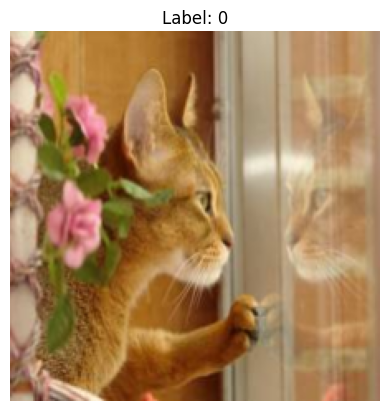

In [37]:
from torch.utils.data import DataLoader

batch_size = 32

nw = max(2, os.cpu_count() * 3 // 4)

# Load some images
train_loader = DataLoader(train, batch_size=batch_size, shuffle=True, num_workers=nw)
validation_loader = DataLoader(validation, batch_size=batch_size, shuffle=False, num_workers=nw)
test_loader = DataLoader(test, batch_size=batch_size, shuffle=False, num_workers=nw)


# Visualize image
import matplotlib.pyplot as plt
import numpy as np
plt.imshow(np.transpose(train[15][0].numpy(), (1, 2, 0)))
plt.title(f"Label: {train[0][1]}")
plt.axis('off')
plt.show()


In [38]:
mean = 0.
std = 0.
total_images_count = 0

for images, _ in train_loader:
    batch_samples = images.size(0)
    images = images.view(batch_samples, images.size(1), -1)  # (B, C, H*W)
    mean += images.mean(2).sum(0)
    std += images.std(2).sum(0)
    total_images_count += batch_samples

mean /= total_images_count
std /= total_images_count

print(f"Mean: {mean.tolist()}")
print(f"Std: {std.tolist()}")

Mean: [0.48447394371032715, 0.45291826128959656, 0.39585861563682556]
Std: [0.22616341710090637, 0.2236108034849167, 0.22575609385967255]


DROPOUT

DATA AUGMENTATION

AUMENTO BASE CHANNEL DIMINUENDO IMAGE SIZE

AGGIUNGERE BLOCCO CONVOLUZIONALE

In [34]:
from torch.nn.functional import cross_entropy
from torch.optim import AdamW
from tqdm import tqdm
from torch.optim.lr_scheduler import OneCycleLR
num_classes = 37
epochs = 150
input_size = 3 * image_size * image_size  # 3 channels, 128x128 pixels
base_channels = 32
model_name = "try_add_block_&_DATA_AUGMENTATION"
save_freq = 15
save_best = True

device = get_device()
print(f"Using device: {device}")

# model = BaseConvModel(num_classes, base_channels).to(device)
# model = DoubleConvModel(num_classes, base_channels).to(device)
# model = StrideConvModel(num_classes, base_channels).to(device)
model = TripleConvModel(num_classes, base_channels).to(device)
total_params = sum(p.numel() for p in model.parameters())
print(f"Numero totale di parametri: {total_params}")

criterion = cross_entropy
optimizer = AdamW(model.parameters(), weight_decay=1e-4)
lr_scheduler = OneCycleLR(optimizer, max_lr=0.0015, steps_per_epoch=len(train_loader), epochs=epochs)

losses = []
val_losses = []
val_accuracies = []
for epoch in range(epochs):
    model.train()
    epoch_loss = 0.0

    for imgs, labels in tqdm(train_loader):

        imgs = imgs.to(device)
        labels = labels.to(device)

        preds = model(imgs)

        # compute gradients
        loss = criterion(preds, labels)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        lr_scheduler.step()


        epoch_loss += loss.item()

    epoch_loss /= len(train_loader)
    losses.append(epoch_loss)
    print(f"Epoch {epoch + 1}/{epochs}, Loss: {epoch_loss:.6f}")

    save_model(model, f"./checkpoints/{model_name}", epoch=epoch, best=False,epoch_freq=save_freq)

    # Validation
    model.eval()
    val_loss = 0.0
    total = 0
    correct = 0
    with torch.no_grad():
        for imgs, labels in validation_loader:
            imgs = imgs.to(device)
            labels = labels.to(device)

            preds = model(imgs)
            loss = criterion(preds, labels)
            val_loss += loss.item()


            _, predicted = torch.max(preds, dim=1)       # prendo la classe con probabilità più alta
            correct += (predicted == labels).sum().item()
            total += labels.size(0)

    val_loss /= len(validation_loader)
    val_losses.append(val_loss)
    print(f"Validation Loss: {val_loss:.6f}")


    val_accuracy = correct / total
    val_accuracies.append(val_accuracy)
    print(f"Validation Accuracy: {val_accuracy:.6f}")

    if save_best and val_loss <= min(val_losses, default=float('inf')):
        save_model(model, f"./checkpoints/{model_name}", epoch=epoch, best=True, epoch_freq=0)


Using device: cuda
Numero totale di parametri: 1405925


100%|██████████| 115/115 [00:22<00:00,  5.04it/s]


Epoch 1/130, Loss: 3.545366
Saving last model to ./checkpoints/try_add_block
Saving model at epoch 0 to ./checkpoints/try_add_block
Validation Loss: 3.493652
Validation Accuracy: 0.074700
Saving best model at epoch 0 to ./checkpoints/try_add_block


100%|██████████| 115/115 [00:22<00:00,  5.03it/s]


Epoch 2/130, Loss: 3.427278
Saving last model to ./checkpoints/try_add_block
Validation Loss: 3.440623
Validation Accuracy: 0.092694
Saving best model at epoch 1 to ./checkpoints/try_add_block


100%|██████████| 115/115 [00:22<00:00,  5.03it/s]

... (264 outputs left out)

100%|██████████| 115/115 [00:22<00:00,  5.01it/s]


Epoch 129/130, Loss: 0.000542
Saving last model to ./checkpoints/try_add_block
Validation Loss: 2.220595
Validation Accuracy: 0.593784


100%|██████████| 115/115 [00:22<00:00,  5.00it/s]


Epoch 130/130, Loss: 0.000738
Saving last model to ./checkpoints/try_add_block
Validation Loss: 2.172705
Validation Accuracy: 0.595965


In [39]:
from torch.nn.functional import cross_entropy
from torch.optim import AdamW
from tqdm import tqdm
from torch.optim.lr_scheduler import OneCycleLR
num_classes = 37
epochs = 150
input_size = 3 * image_size * image_size  # 3 channels, 128x128 pixels
base_channels = 32
model_name = "try_add_block_&_DATA_AUGMENTATION"
save_freq = 15
save_best = True

device = get_device()
print(f"Using device: {device}")

# model = BaseConvModel(num_classes, base_channels).to(device)
# model = DoubleConvModel(num_classes, base_channels).to(device)
# model = StrideConvModel(num_classes, base_channels).to(device)
model = TripleConvModel(num_classes, base_channels).to(device)
total_params = sum(p.numel() for p in model.parameters())
print(f"Numero totale di parametri: {total_params}")

criterion = cross_entropy
optimizer = AdamW(model.parameters())
lr_scheduler = OneCycleLR(optimizer, max_lr=0.0015, steps_per_epoch=len(train_loader), epochs=epochs)

losses = []
val_losses = []
val_accuracies = []
for epoch in range(epochs):
    model.train()
    epoch_loss = 0.0

    for imgs, labels in tqdm(train_loader):

        imgs = imgs.to(device)
        labels = labels.to(device)

        preds = model(imgs)

        # compute gradients
        loss = criterion(preds, labels)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        lr_scheduler.step()


        epoch_loss += loss.item()

    epoch_loss /= len(train_loader)
    losses.append(epoch_loss)
    print(f"Epoch {epoch + 1}/{epochs}, Loss: {epoch_loss:.6f}")

    save_model(model, f"./checkpoints/{model_name}", epoch=epoch, best=False,epoch_freq=save_freq)

    # Validation
    model.eval()
    val_loss = 0.0
    total = 0
    correct = 0
    with torch.no_grad():
        for imgs, labels in validation_loader:
            imgs = imgs.to(device)
            labels = labels.to(device)

            preds = model(imgs)
            loss = criterion(preds, labels)
            val_loss += loss.item()


            _, predicted = torch.max(preds, dim=1)       # prendo la classe con probabilità più alta
            correct += (predicted == labels).sum().item()
            total += labels.size(0)

    val_loss /= len(validation_loader)
    val_losses.append(val_loss)
    print(f"Validation Loss: {val_loss:.6f}")


    val_accuracy = correct / total
    val_accuracies.append(val_accuracy)
    print(f"Validation Accuracy: {val_accuracy:.6f}")

    if save_best and val_loss <= min(val_losses, default=float('inf')):
        save_model(model, f"./checkpoints/{model_name}", epoch=epoch, best=True, epoch_freq=0)


Using device: cuda
Numero totale di parametri: 1405925


100%|██████████| 115/115 [00:23<00:00,  4.98it/s]


Epoch 1/150, Loss: 3.560447
Saving last model to ./checkpoints/try_add_block_&_DATA_AUGMENTATION
Saving model at epoch 0 to ./checkpoints/try_add_block_&_DATA_AUGMENTATION
Validation Loss: 3.530385
Validation Accuracy: 0.065431
Saving best model at epoch 0 to ./checkpoints/try_add_block_&_DATA_AUGMENTATION


100%|██████████| 115/115 [00:22<00:00,  5.01it/s]


Epoch 2/150, Loss: 3.437380
Saving last model to ./checkpoints/try_add_block_&_DATA_AUGMENTATION
Validation Loss: 3.462509
Validation Accuracy: 0.069248
Saving best model at epoch 1 to ./checkpoints/try_add_block_&_DATA_AUGMENTATION


100%|██████████| 115/115 [00:22<00:00,  5.04it/s]


... (290 outputs left out)

100%|██████████| 115/115 [00:22<00:00,  5.02it/s]


Epoch 140/150, Loss: 0.000405
Saving last model to ./checkpoints/try_add_block_&_DATA_AUGMENTATION
Validation Loss: 2.130620
Validation Accuracy: 0.577426


 11%|█▏        | 13/115 [00:03<00:25,  4.08it/s]


KeyboardInterrupt: 

In [ ]:
optimizer = AdamW(model.parameters(), lr=0.00005, weight_decay=4e-5)

for epoch in range(40):
    model.train()
    epoch_loss = 0.0

    for imgs, labels in tqdm(train_loader):

        imgs = imgs.to(device)
        labels = labels.to(device)

        preds = model(imgs)

        # compute gradients
        loss = criterion(preds, labels, label_smoothing=0.1)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()


        epoch_loss += loss.item()

    epoch_loss /= len(train_loader)
    losses.append(epoch_loss)
    print(f"Epoch {epoch + 1}/{epochs}, Loss: {epoch_loss:.6f}")

    save_model(model, f"./checkpoints/{model_name}", epoch=epoch, best=False,epoch_freq=save_freq)

    # Validation
    model.eval()
    val_loss = 0.0
    total = 0
    correct = 0
    with torch.no_grad():
        for imgs, labels in validation_loader:
            imgs = imgs.to(device)
            labels = labels.to(device)

            preds = model(imgs)
            loss = criterion(preds, labels)
            val_loss += loss.item()

            _, predicted = torch.max(preds, dim=1)       # prendo la classe con probabilità più alta
            correct += (predicted == labels).sum().item()
            total += labels.size(0)

    val_loss /= len(validation_loader)
    val_losses.append(val_loss)
    print(f"Validation Loss: {val_loss:.6f}")

    val_accuracy = correct / total
    val_accuracies.append(val_accuracy)
    print(f"Validation Accuracy: {val_accuracy:.6f}")

    if save_best and val_loss <= min(val_losses, default=float('inf')):
        save_model(model, f"./checkpoints/{model_name}", epoch=epoch, best=True, epoch_freq=0)

100%|██████████| 115/115 [00:23<00:00,  4.86it/s]


Epoch 1/150, Loss: 1.764586
Saving last model to ./checkpoints/try_res_net_like
Saving model at epoch 0 to ./checkpoints/try_res_net_like
Validation Loss: 2.169708
Validation Accuracy: 0.525082


100%|██████████| 115/115 [00:23<00:00,  4.94it/s]

Epoch 2/150, Loss: 1.653787
Saving last model to ./checkpoints/try_res_net_like


Validation Loss: 2.081353
Validation Accuracy: 0.531080


100%|██████████| 115/115 [00:23<00:00,  4.97it/s]

... (107 outputs left out)

Validation Loss: 1.771769
Validation Accuracy: 0.528899
Saving best model at epoch 38 to ./checkpoints/try_res_net_like


100%|██████████| 115/115 [00:23<00:00,  4.94it/s]

Epoch 40/150, Loss: 1.068574
Saving last model to ./checkpoints/try_res_net_like


Validation Loss: 1.788575
Validation Accuracy: 0.521810


In [ ]:
import matplotlib.pyplot as plt

plt.plot(range(len(losses)), losses, label='Training Loss', color='blue')
plt.plot(range(len(val_losses)), val_losses, label='Validation Loss', color='orange')
plt.plot(range(len(val_accuracies)), val_accuracies, label='Validation Accuracy', color='green')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training & Validation Loss')
plt.legend()
plt.show()

BEST MODEL: TRY_ADD_BLOCK, IMAGE_SIZE=224, BASE_CHANNEL=32, DATA_AUGMENTATION=only horizontal clip 0.5,

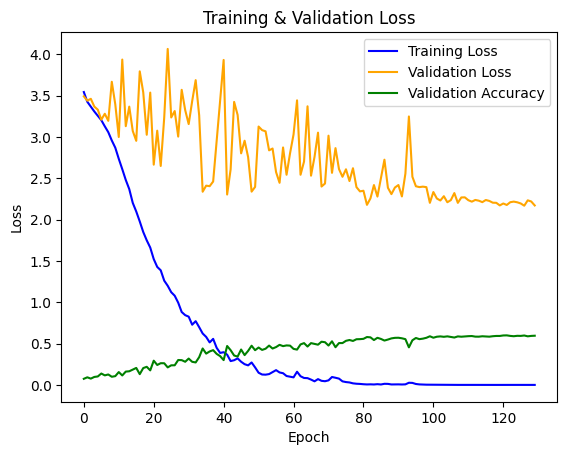

In [35]:
import matplotlib.pyplot as plt

plt.plot(range(len(losses)), losses, label='Training Loss', color='blue')
plt.plot(range(len(val_losses)), val_losses, label='Validation Loss', color='orange')
plt.plot(range(len(val_accuracies)), val_accuracies, label='Validation Accuracy', color='green')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training & Validation Loss')
plt.legend()
plt.show()

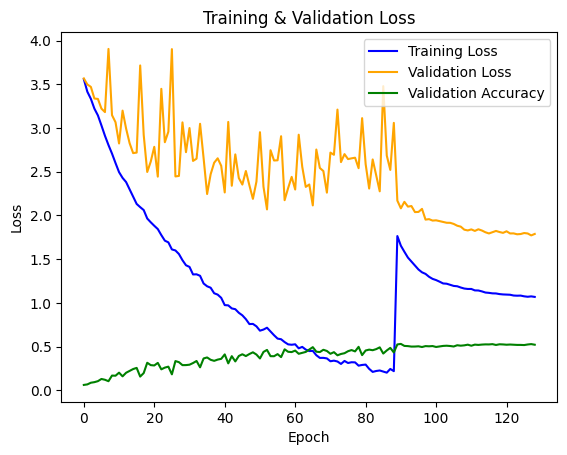

In [ ]:
import matplotlib.pyplot as plt

plt.plot(range(len(losses)), losses, label='Training Loss', color='blue')
plt.plot(range(len(val_losses)), val_losses, label='Validation Loss', color='orange')
plt.plot(range(len(val_accuracies)), val_accuracies, label='Validation Accuracy', color='green')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training & Validation Loss')
plt.legend()
plt.show()

In [37]:
model.eval()
correct = 0
total = 0
with torch.no_grad():
    for imgs, labels in tqdm(test_loader):
        imgs = imgs.to(device)
        labels = labels.to(device)

        preds = model(imgs)
        _, predicted = torch.max(preds, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()
accuracy = correct / total
print(f"Test Accuracy: {accuracy:.4f}")


100%|██████████| 58/58 [00:04<00:00, 13.75it/s]

Test Accuracy: 0.6213


In [13]:
from torch.nn.functional import cross_entropy
from torch.optim import AdamW
from tqdm import tqdm
from torch.optim.lr_scheduler import OneCycleLR

In [26]:
model_name = "try_add_block"
num_classes = 37
base_channels = 32
device = get_device()
print(f"Using device: {device}")
model_best = TripleConvModel(num_classes, base_channels).to(device)
model_best.load_state_dict(torch.load(f"./checkpoints/{model_name}/best_model.pt"))

model_best.eval()
correct = 0
total = 0
with torch.no_grad():
    for imgs, labels in tqdm(test_loader):
        imgs = imgs.to(device)
        labels = labels.to(device)

        preds = model_best(imgs)
        _, predicted = torch.max(preds, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()
accuracy = correct / total
print(f"Test Accuracy: {accuracy:.4f}")

Using device: cuda


100%|██████████| 58/58 [00:04<00:00, 13.74it/s]

Test Accuracy: 0.6262


## Part 2: fine-tune an existing network

Your goal is to fine-tune a pretrained ResNet-18 model on `OxfordPetDataset`. Use the implementation provided by PyTorch, i.e. the opposite of part 1. Specifically, use the PyTorch ResNet-18 model pretrained on ImageNet-1K (V1). Divide your fine-tuning into two parts:

2A. First, fine-tune the ResNet-18 with the same training hyperparameters you used for your best model in part 1.

2B. Then, tweak the training hyperparameters in order to increase the accuracy on the test split. Justify your choices by analyzing the training plots and/or citing sources that guided you in your decisions — papers, blog posts, YouTube videos, or whatever else you may find useful. You should consider yourselves satisfied once you obtain a classification accuracy on the test split of ~90%.